**Healthcare Predictive Analytics - Disease Prediction**

In this project we will build a simple predictive model to predict a patient's medical condition (disease) based on their information like age, gender, blood type, test results etc. We will use the cleaned healthcare dataset from Assignment 1.

**Import Libraries**

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

**Load the dataset**

In [2]:
df = pd.read_csv('/content/healthcare_dataset_cleaned.csv')
df.head()

,Name,Age,Gender,Blood Type,Medical Condition,Date of Admission,Doctor,Hospital,Insurance Provider,Billing Amount,Room Number,Admission Type,Discharge Date,Medication,Test Results,Length_of_Stay
0,Bobby Jackson,30,Male,B-,Cancer,2024-01-31,Matthew Smith,Sons and Miller,Blue Cross,18856.281306,328,Urgent,2024-02-02,Paracetamol,Normal,2
1,Leslie Terry,62,Male,A+,Obesity,2019-08-20,Samantha Davies,Kim Inc,Medicare,33643.327287,265,Emergency,2019-08-26,Ibuprofen,Inconclusive,6
2,Danny Smith,76,Female,A-,Obesity,2022-09-22,Tiffany Mitchell,Cook PLC,Aetna,27955.096079,205,Emergency,2022-10-07,Aspirin,Normal,15
3,Andrew Watts,28,Female,O+,Diabetes,2020-11-18,Kevin Wells,"Hernandez Rogers and Vang,",Medicare,37909.782410,450,Elective,2020-12-18,Ibuprofen,Abnormal,30
4,Adrienne Bell,43,Female,AB+,Cancer,2022-09-19,Kathleen Hanna,White-White,Aetna,14238.317814,458,Urgent,2022-10-09,Penicillin,Abnormal,20


In [3]:
df.shape

(54966, 16)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 54966 entries, 0 to 54965
Data columns (total 16 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Name                54966 non-null  object 
 1   Age                 54966 non-null  int64  
 2   Gender              54966 non-null  object 
 3   Blood Type          54966 non-null  object 
 4   Medical Condition   54966 non-null  object 
 5   Date of Admission   54966 non-null  object 
 6   Doctor              54966 non-null  object 
 7   Hospital            54966 non-null  object 
 8   Insurance Provider  54966 non-null  object 
 9   Billing Amount      54966 non-null  float64
 10  Room Number         54966 non-null  int64  
 11  Admission Type      54966 non-null  object 
 12  Discharge Date      54966 non-null  object 
 13  Medication          54966 non-null  object 
 14  Test Results        54966 non-null  object 
 15  Length_of_Stay      54966 non-null  int64  
dtypes: f

**Check what we are predicting**

In [5]:
# we want to predict the Medical Condition (disease)
print("Diseases in the dataset:")
print(df['Medical Condition'].value_counts())

Diseases in the dataset:
Medical Condition
Arthritis       9218
Diabetes        9216
Hypertension    9151
Obesity         9146
Cancer          9140
Asthma          9095
Name: count, dtype: int64


---
## **Step 1: Select the features (columns) for prediction**

In [6]:
# we will use these columns to predict the disease
# we cannot use Name, Doctor, Hospital etc because they are just text
# we will use: Age, Gender, Blood Type, Admission Type, Test Results, Billing Amount

features = ['Age', 'Gender', 'Blood Type', 'Admission Type', 'Test Results', 'Billing Amount']
target = 'Medical Condition'

print("Features (input):", features)
print("Target (what we predict):", target)

Features (input): ['Age', 'Gender', 'Blood Type', 'Admission Type', 'Test Results', 'Billing Amount']
Target (what we predict): Medical Condition


---
## **Step 2: Convert text columns to numbers**

**Machine learning models only work with numbers, so we need to convert text columns like Gender, Blood Type etc into numbers**

In [7]:
# make a copy so we dont change the original data
df_model = df[features + [target]].copy()

df_model.head()

,Age,Gender,Blood Type,Admission Type,Test Results,Billing Amount,Medical Condition
0,30,Male,B-,Urgent,Normal,18856.281306,Cancer
1,62,Male,A+,Emergency,Inconclusive,33643.327287,Obesity
2,76,Female,A-,Emergency,Normal,27955.096079,Obesity
3,28,Female,O+,Elective,Abnormal,37909.782410,Diabetes
4,43,Female,AB+,Urgent,Abnormal,14238.317814,Cancer


In [8]:
# use LabelEncoder to convert text to numbers
le_gender = LabelEncoder()
le_blood = LabelEncoder()
le_admission = LabelEncoder()
le_test = LabelEncoder()
le_target = LabelEncoder()

df_model['Gender'] = le_gender.fit_transform(df_model['Gender'])
df_model['Blood Type'] = le_blood.fit_transform(df_model['Blood Type'])
df_model['Admission Type'] = le_admission.fit_transform(df_model['Admission Type'])
df_model['Test Results'] = le_test.fit_transform(df_model['Test Results'])
df_model['Medical Condition'] = le_target.fit_transform(df_model['Medical Condition'])

print("Converted! Now all columns are numbers:")
df_model.head()

Converted! Now all columns are numbers:


,Age,Gender,Blood Type,Admission Type,Test Results,Billing Amount,Medical Condition
0,30,1,5,2,2,18856.281306,2
1,62,1,0,1,1,33643.327287,5
2,76,0,1,1,2,27955.096079,5
3,28,0,6,0,0,37909.782410,3
4,43,0,2,2,0,14238.317814,2


**See what the encoding looks like**

In [9]:
print("Gender:", list(le_gender.classes_))
print("Blood Type:", list(le_blood.classes_))
print("Admission Type:", list(le_admission.classes_))
print("Test Results:", list(le_test.classes_))
print("Medical Condition (Target):", list(le_target.classes_))

Gender: ['Female', 'Male']
Blood Type: ['A+', 'A-', 'AB+', 'AB-', 'B+', 'B-', 'O+', 'O-']
Admission Type: ['Elective', 'Emergency', 'Urgent']
Test Results: ['Abnormal', 'Inconclusive', 'Normal']
Medical Condition (Target): ['Arthritis', 'Asthma', 'Cancer', 'Diabetes', 'Hypertension', 'Obesity']


---
## **Step 3: Split data into Training and Testing sets**

**We use 80% of data to train the model and 20% to test it**

In [10]:
# X = features (input), y = target (what we predict)
X = df_model[features]
y = df_model[target]

# split into train (80%) and test (20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Training data size:", X_train.shape[0])
print("Testing data size:", X_test.shape[0])

Training data size: 43972
Testing data size: 10994


---
## **Step 4: Build the Prediction Models**

**Model 1: Decision Tree Classifier**

In [11]:
# create the decision tree model
dt_model = DecisionTreeClassifier(random_state=42)

# train the model using training data
dt_model.fit(X_train, y_train)

# make predictions on test data
dt_predictions = dt_model.predict(X_test)

# check accuracy
dt_accuracy = accuracy_score(y_test, dt_predictions)
print("Decision Tree Accuracy:", round(dt_accuracy * 100, 2), "%")

Decision Tree Accuracy: 22.67 %


**Model 2: Logistic Regression**

In [12]:
# create the logistic regression model
lr_model = LogisticRegression(max_iter=1000, random_state=42)

# train the model
lr_model.fit(X_train, y_train)

# make predictions
lr_predictions = lr_model.predict(X_test)

# check accuracy
lr_accuracy = accuracy_score(y_test, lr_predictions)
print("Logistic Regression Accuracy:", round(lr_accuracy * 100, 2), "%")

Logistic Regression Accuracy: 16.51 %


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


---
## **Step 5: Compare the Two Models**

In [13]:
print("Model Comparison:")
print("Decision Tree Accuracy:", round(dt_accuracy * 100, 2), "%")
print("Logistic Regression Accuracy:", round(lr_accuracy * 100, 2), "%")
print()
if dt_accuracy > lr_accuracy:
    print("Decision Tree performs better!")
elif lr_accuracy > dt_accuracy:
    print("Logistic Regression performs better!")
else:
    print("Both models have same accuracy!")

Model Comparison:
Decision Tree Accuracy: 22.67 %
Logistic Regression Accuracy: 16.51 %

Decision Tree performs better!


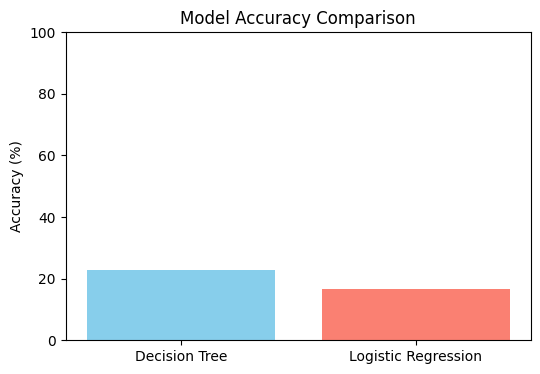

In [14]:
# bar chart comparing model accuracy
models = ['Decision Tree', 'Logistic Regression']
accuracies = [dt_accuracy * 100, lr_accuracy * 100]

plt.figure(figsize=(6, 4))
plt.bar(models, accuracies, color=['skyblue', 'salmon'])
plt.ylabel('Accuracy (%)')
plt.title('Model Accuracy Comparison')
plt.ylim(0, 100)
plt.show()

---
## **Step 6: Evaluate the Better Model in Detail**

**Classification Report - shows precision, recall and f1-score for each disease**

In [15]:
# using decision tree for detailed evaluation
print("Classification Report (Decision Tree):")
print()
print(classification_report(y_test, dt_predictions, target_names=le_target.classes_))

Classification Report (Decision Tree):

              precision    recall  f1-score   support

   Arthritis       0.24      0.24      0.24      1867
      Asthma       0.23      0.23      0.23      1823
      Cancer       0.22      0.22      0.22      1830
    Diabetes       0.24      0.23      0.23      1886
Hypertension       0.21      0.23      0.22      1757
     Obesity       0.23      0.21      0.22      1831

    accuracy                           0.23     10994
   macro avg       0.23      0.23      0.23     10994
weighted avg       0.23      0.23      0.23     10994



**Confusion Matrix - shows how many predictions were correct vs wrong**

In [16]:
cm = confusion_matrix(y_test, dt_predictions)
print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[444 271 281 287 296 288]
 [279 425 265 257 321 276]
 [293 293 394 295 312 243]
 [280 291 295 429 312 279]
 [276 270 273 280 412 246]
 [292 301 266 263 321 388]]


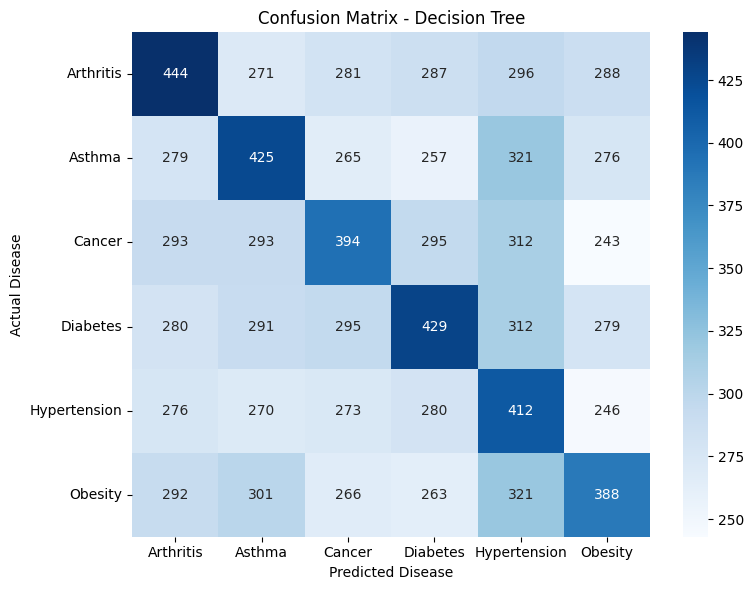

In [17]:
# visualize confusion matrix as a heatmap
import seaborn as sns

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=le_target.classes_,
            yticklabels=le_target.classes_)
plt.xlabel('Predicted Disease')
plt.ylabel('Actual Disease')
plt.title('Confusion Matrix - Decision Tree')
plt.tight_layout()
plt.show()

---
## **Step 7: Feature Importance**

**Which features are most important for predicting disease?**

In [18]:
# decision tree can tell us which features matter the most
importance = dt_model.feature_importances_
feature_importance = pd.Series(importance, index=features).sort_values(ascending=False)

print("Feature Importance:")
print(feature_importance.round(4))

Feature Importance:
Billing Amount    0.4572
Age               0.2261
Blood Type        0.1420
Test Results      0.0622
Gender            0.0594
Admission Type    0.0531
dtype: float64


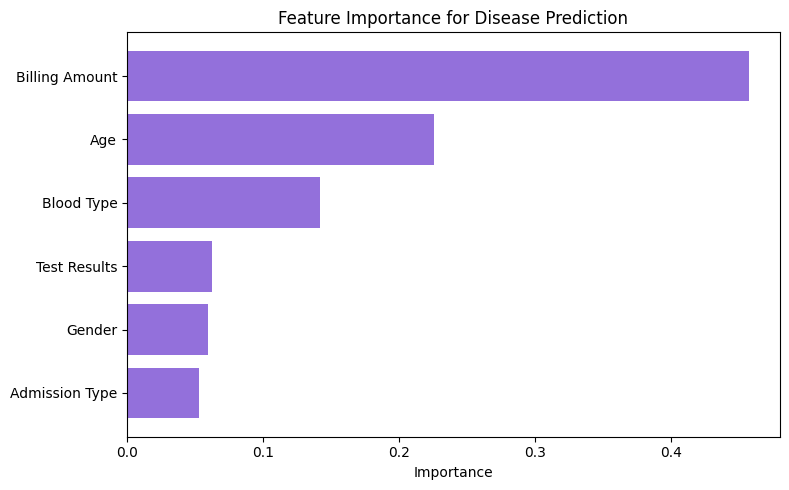

In [19]:
plt.figure(figsize=(8, 5))
plt.barh(feature_importance.index[::-1], feature_importance.values[::-1], color='mediumpurple')
plt.xlabel('Importance')
plt.title('Feature Importance for Disease Prediction')
plt.tight_layout()
plt.show()

---
## **Step 8: Test the Model with New Patient Data**

In [20]:
# lets test our model with a sample patient
# Age=45, Gender=Male(1), Blood Type=A+(1), Admission=Emergency(0), Test=Abnormal(0), Billing=25000

sample_patient = [[45, 1, 1, 0, 0, 25000]]
prediction = dt_model.predict(sample_patient)
predicted_disease = le_target.inverse_transform(prediction)

print("Sample Patient: Age=45, Male, Blood Type A+, Emergency Admission, Abnormal Test, Bill=$25000")
print("Predicted Disease:", predicted_disease[0])

Sample Patient: Age=45, Male, Blood Type A+, Emergency Admission, Abnormal Test, Bill=$25000
Predicted Disease: Asthma


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


In [21]:
# test with another patient
# Age=65, Gender=Female(0), Blood Type=O+(6), Admission=Urgent(2), Test=Normal(2), Billing=40000

sample_patient2 = [[65, 0, 6, 2, 2, 40000]]
prediction2 = dt_model.predict(sample_patient2)
predicted_disease2 = le_target.inverse_transform(prediction2)

print("Sample Patient: Age=65, Female, Blood Type O+, Urgent Admission, Normal Test, Bill=$40000")
print("Predicted Disease:", predicted_disease2[0])

Sample Patient: Age=65, Female, Blood Type O+, Urgent Admission, Normal Test, Bill=$40000
Predicted Disease: Asthma


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


---
## **Summary**

In [22]:
print("SUMMARY")
print()
print("Problem: Predict a patient's disease based on their information")
print("Dataset: Healthcare dataset with", len(df), "patient records")
print("Target: Medical Condition (6 diseases)")
print("Features used:", features)
print()
print("Models Built:")
print("  1. Decision Tree -", round(dt_accuracy * 100, 2), "% accuracy")
print("  2. Logistic Regression -", round(lr_accuracy * 100, 2), "% accuracy")
print()
print("Most Important Feature:", feature_importance.index[0])
print()
print("Note: The accuracy is low because this is a synthetic dataset where")
print("diseases are randomly distributed. In real healthcare data the model")
print("would perform much better as there would be real patterns between")
print("patient features and diseases.")

SUMMARY

Problem: Predict a patient's disease based on their information
Dataset: Healthcare dataset with 54966 patient records
Target: Medical Condition (6 diseases)
Features used: ['Age', 'Gender', 'Blood Type', 'Admission Type', 'Test Results', 'Billing Amount']

Models Built:
  1. Decision Tree - 22.67 % accuracy
  2. Logistic Regression - 16.51 % accuracy

Most Important Feature: Billing Amount

Note: The accuracy is low because this is a synthetic dataset where
diseases are randomly distributed. In real healthcare data the model
would perform much better as there would be real patterns between
patient features and diseases.
